# 15장 노이즈 라벨 대응

13장에서 Jev 오라클의 라벨은 NSMC에서 약 10%, YNAT에서 약 16%가 정답 라벨과 달랐다. 엔트로피로 고른 어려운 문장에서는 더 자주 틀려서, YNAT 루프의 누적 노이즈율이 26%에 이르렀다. 이 장은 틀린 라벨을 두 길로 다룬다.

- 사람에게 보낸다: 틀렸을 것 같은 라벨만 골라 사람 검수로 보낸다(라우팅).
- 견딘다: 남은 노이즈가 학습을 덜 망치게 한다(샘플 가중, 확률 라벨, 라벨 평활화).

그리고 검수에 돈을 얼마나 쓰면 무엇을 얻는지 절충 곡선으로 본다.

- 15.1 LLM 라벨 노이즈의 유형
- 15.2 사람 검수 라우팅
- 15.3 학생 모델과 오라클의 불일치 탐지
- 15.4 노이즈 강건 학습 — 샘플 가중과 라벨 평활화
- 15.5 검수 예산과 라벨 정확도의 절충

질의 전략은 엔트로피, 오라클은 13장의 Jev 오라클이다. 사람 검수는 시뮬레이션이다. 검수된 라벨은 정답 라벨로 바뀌고 00_기획안 4.2절의 검수 단가(라벨 단가의 60%)가 든다. 신뢰도는 14장에서 고른 선택지 확률을 쓴다. Jev 호출에 필요한 키·주소·모델 이름은 `jupyter/.env` 에서만 읽는다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


질의 전략으로 쓸 3장의 엔트로피 점수를 다시 싣는다.

In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

query_entropy = make_score_query(score_entropy)

Jev 호출 함수, 라벨 체계, 요청 형식, 라벨 판정 함수는 13장과 같다. 이 장은 실험이 길어 연결이 끊기는 일이 있었으므로 호출 함수에 연결 오류 재시도를 더했다.

In [3]:
# ── Jev 호출 함수 ────
import os
import requests
from dotenv import load_dotenv
from concurrent.futures import ThreadPoolExecutor

load_dotenv(".env")                      # jupyter/.env — 키·주소·모델 이름은 여기에만 있다
print({n: bool(os.getenv(n)) for n in ("JEV_API_KEY", "JEV_BASE_URL", "JEV_MODEL")})   # 값은 출력하지 않는다

JEV = dict(key=os.environ["JEV_API_KEY"], url=os.environ["JEV_BASE_URL"].rstrip("/"), model=os.environ["JEV_MODEL"])
MAX_CONC = 5                             # 동시 호출 수
SESSION = requests.Session()

def mask(text):
    # 오류 메시지에 키·주소·모델 이름이 섞여 나오지 않도록 가린다
    for v in JEV.values():
        text = text.replace(v, "***")
    return text

def jev_ask(state, questions):
    # 판정 질문 묶음을 한 번 보내고 (질문 이름별 답, 입력 토큰, 출력 토큰)을 돌려준다
    body = dict(model=JEV["model"], state=state, questions=questions)
    for wait in (2, 4, 8, 16, 32, 64, 120, 240, 480, 600):   # 일시 오류·연결 끊김은 쉬었다 다시 보낸다(최대 약 26분)
        try:
            r = SESSION.post(f"{JEV['url']}/v1/systemone", headers={"Authorization": f"Bearer {JEV['key']}"},
                             json=body, timeout=300)
        except requests.ConnectionError:                    # 오래 도는 실험에서 연결이 끊기면 잠시 쉬고 다시 보낸다
            time.sleep(wait)
            continue
        if r.status_code == 200:
            j = r.json()
            return j["answers"], j["usage"]["input_tokens"], j["usage"]["output_tokens"]
        time.sleep(wait)
    raise RuntimeError(mask(f"Jev 응답 {r.status_code}: {r.text[:300]}"))

{'JEV_API_KEY': True, 'JEV_BASE_URL': True, 'JEV_MODEL': True}


In [4]:
# ── 라벨 체계 ────
LABEL_NAMES = {"nsmc": ["부정", "긍정"],
               "ynat": ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]}
LABEL_DESC = {"nsmc": {"부정": "영화를 부정적으로 평가한 리뷰", "긍정": "영화를 긍정적으로 평가한 리뷰"},
              "ynat": {"IT과학": "정보기술·과학 기사", "경제": "경제·산업·금융 기사", "사회": "사건·사고·사회 기사",
                       "생활문화": "생활·문화·건강·여행 기사", "세계": "국제·해외 기사", "스포츠": "스포츠 기사",
                       "정치": "정치·외교·북한 기사"}}
TASK = {"nsmc": "영화 리뷰의 감성", "ynat": "뉴스 기사 제목의 주제"}

In [5]:
# ── 검증 집합 ────
# 라벨 정확도·신뢰도는 루프와 떼어 검증 집합 2,000개에서 잰다. 시험 집합은 학생 모델 평가에만 쓴다
VAL = {name: pd.read_csv(f"data/{name}_val.csv") for name in DATA}
for name, v in VAL.items():
    print(name, "검증", len(v), "클래스별", np.bincount(v.label).tolist())

nsmc 검증 2000 클래스별 [1003, 997]
ynat 검증 2000 클래스별 [229, 268, 225, 252, 364, 339, 323]


In [6]:
# ── 라벨 스키마와 요청 만들기 ────
CHUNK = 50                               # 요청 하나에 넣는 문장 수
TASK_SENT = {"nsmc": "영화 리뷰의 감성을 분류한다.", "ynat": "뉴스 기사 제목의 주제를 분류한다."}
RULES = {"nsmc": ["반어나 비꼼으로 칭찬하는 척하는 리뷰는 부정이다",
                  "칭찬과 불만이 섞이면 글쓴이의 최종 평가를 따른다",
                  "영화 밖의 이야기(배우, 다른 관객)라도 영화에 대한 태도가 드러나면 그 태도를 따른다"],
         "ynat": ["기업·산업·시장·금융·부동산은 경제다. IT 제품·통신·인터넷 서비스·과학 연구는 IT과학이다",
                  "사건·사고·교육·노동·법원·지역 소식은 사회다",
                  "국내 정치·국회·정당·외교·북한은 정치다. 외국 정부와 해외에서 일어난 일은 세계다",
                  "문화·연예·건강·여행·종교·생활 정보는 생활문화다",
                  "경기 결과·선수·구단·대회는 스포츠다"]}

def schema_text(name, level):
    # level 0: 라벨 이름만, 1: 라벨 설명, 2: 설명 + 경계 규칙
    lines = [f"과제: {TASK_SENT[name]}", "라벨:"]
    lines += [f"- {n}: {LABEL_DESC[name][n]}" if level >= 1 else f"- {n}" for n in LABEL_NAMES[name]]
    lines += ["경계 규칙:"] + [f"- {r}" for r in RULES[name]] if level == 2 else []
    return "\n".join(lines)

def build_request(name, texts, schema=1, rich=False, shots=(), near=None):
    # state = 스키마 → 퓨샷 예시 → 분류할 문장. 질문은 문장마다 label_i 하나
    one = lambda t: str(t).replace("\n", " ")
    parts = [] if schema is None else [schema_text(name, schema)]
    parts += ["예시:\n" + "\n".join(f'- "{one(t)}" → {y}' for t, y in shots)] if len(shots) else []
    items = [f"[{i}] {one(t)}" + ("" if near is None else "\n    비슷한 예시: " + "; ".join(f'"{one(a)}" → {b}' for a, b in near[i]))
             for i, t in enumerate(texts)]
    state = "\n\n".join(parts + ["분류할 문장:\n" + "\n".join(items)])
    crit = LABEL_DESC[name] if rich else {n: None for n in LABEL_NAMES[name]}
    ask = f"{TASK[name]}은?" if rich else "라벨"
    qs = {f"label_{i}": {"type": "choice", "instructions": f"[{i}]번 문장의 {ask}", "criteria": crit} for i in range(len(texts))}
    return state, qs

In [7]:
# ── Jev 라벨 판정 ────
def jev_label(name, texts, cfg, near=None):
    # texts를 50개씩 묶어 판정한다. (선택지 확률 행렬, 답의 confidence, 묶음별 사용량)을 돌려준다
    names = LABEL_NAMES[name]
    def one(s):
        state, qs = build_request(name, texts[s:s + CHUNK], near=None if near is None else near[s:s + CHUNK], **cfg)
        t0 = time.perf_counter()
        ans, a, b = jev_ask(state, qs)
        P = [[ans[f"label_{i}"]["probabilities"].get(n, 0.0) for n in names] for i in range(len(qs))]
        c = [ans[f"label_{i}"]["confidence"] for i in range(len(qs))]
        return P, c, dict(n_in=a, n_out=b, t=time.perf_counter() - t0, n=len(qs))
    with ThreadPoolExecutor(MAX_CONC) as ex:
        out = list(ex.map(one, range(0, len(texts), CHUNK)))
    P = np.array([p for o in out for p in o[0]])
    return P / P.sum(1, keepdims=True), np.array([c for o in out for c in o[1]]), pd.DataFrame([o[2] for o in out])

In [8]:
# ── 13·14장에서 넘겨받는 설정 ────
BEST = {"nsmc": dict(schema=1, n=8), "ynat": dict(schema=2, n=7)}     # 13장: NSMC S1 + 균형 8, YNAT S2 + 균형 7
TAU = {"nsmc": 0.97, "ynat": 0.84}                                    # 14장: 선택지 확률로 목표 정확도 0.97 / 0.92를 지키는 τ
UNIT = {"nsmc": 50, "ynat": 80}                                       # 00_기획안 4.2절 가정: 사람 라벨 단가(원). 검수는 60%
REVIEW = 0.6

def pick_bal(d, idx0, n, rng):
    y0 = d["y_pool"][idx0]
    pick = np.concatenate([rng.choice(idx0[y0 == c], n // d["n_classes"], replace=False) for c in range(d["n_classes"])])
    return rng.permutation(pick)

def oracle_cfg(d, idx0, seed):
    # 13장 Jev 오라클과 같다: 그 실행의 초기 라벨 100개에서 클래스 균형 예시를 고른다
    pick = pick_bal(d, idx0, BEST[d["name"]]["n"], np.random.default_rng(seed))
    return dict(schema=BEST[d["name"]]["schema"], shots=[(d["texts"][i], LABEL_NAMES[d["name"]][d["y_pool"][i]]) for i in pick])

## 15.1 LLM 라벨 노이즈의 유형

14장의 기본 요청 결과(검증 2,000개)로 Jev 라벨의 오류를 나눈다.

- 클래스 쌍 혼동: 어떤 정답 클래스가 어떤 클래스로 잘못 붙는가
- 신뢰도 구간별 오류: 오류가 낮은 신뢰도에 몰려 있는가
- 고신뢰 오류: 14장 τ 이상의 신뢰도로 틀린 라벨. 신뢰도 라우팅으로는 잡히지 않는다

고신뢰 오류 가운데 일부는 정답 라벨 쪽이 의심스럽다(13장 13.6절). 이 장의 시뮬레이션 검수는 정답 라벨을 그대로 옮기므로, 그런 사례에서는 검수가 맞는 Jev 라벨을 틀린 정답 라벨로 바꾼다.

In [9]:
# ── 오류 구조 ────
for name in DATA:
    df = pd.read_csv(f"results/ch14_parts/static_{name}_rep0.csv")
    P, names = df.filter(regex=r"^p\d").values, LABEL_NAMES[name]
    c, yh = P.max(1), P.argmax(1)
    err = yh != df.y.values
    bins = pd.cut(c, np.unique([0, 0.5, 0.7, 0.9, TAU[name], 1.0001]), right=False)
    t = pd.DataFrame({"n": pd.Series(bins).value_counts(sort=False), "error": pd.Series(err).groupby(bins, observed=False).mean(),
                      "share_of_errors": pd.Series(err).groupby(bins, observed=False).sum() / err.sum()})
    print(f"\n{name} 오류율 {err.mean():.4f} | 신뢰도 구간별 (τ = {TAU[name]})")
    print(t.round(4).to_string())
    print(f"{name} 고신뢰 오류(c ≥ τ): {(err & (c >= TAU[name])).sum()}개, 오류의 {(err & (c >= TAU[name])).sum() / err.sum():.1%}")
    pairs = pd.Series([f"{names[a]}→{names[b]}" for a, b in zip(df.y.values[err], yh[err])]).value_counts()
    print(f"{name} 혼동 쌍 상위 (정답→Jev):", pairs.head(5).to_dict())


nsmc 오류율 0.1020 | 신뢰도 구간별 (τ = 0.97)
                n   error  share_of_errors
[0.0, 0.5)      0     NaN           0.0000
[0.5, 0.7)    163  0.3865           0.3088
[0.7, 0.9)    266  0.2368           0.3088
[0.9, 0.97)   222  0.1532           0.1667
[0.97, 1.0)  1349  0.0326           0.2157
nsmc 고신뢰 오류(c ≥ τ): 44개, 오류의 21.6%
nsmc 혼동 쌍 상위 (정답→Jev): {'부정→긍정': 108, '긍정→부정': 96}

ynat 오류율 0.1560 | 신뢰도 구간별 (τ = 0.84)
                n   error  share_of_errors
[0.0, 0.5)     37  0.5676           0.0673
[0.5, 0.7)    230  0.4783           0.3526
[0.7, 0.84)   216  0.3287           0.2276
[0.84, 0.9)   159  0.1887           0.0962
[0.9, 1.0)   1358  0.0589           0.2564
ynat 고신뢰 오류(c ≥ τ): 110개, 오류의 35.3%
ynat 혼동 쌍 상위 (정답→Jev): {'사회→정치': 36, '경제→IT과학': 34, '사회→경제': 28, '세계→정치': 25, '사회→IT과학': 22}


## 15.2 사람 검수 라우팅

루프의 4단계를 둘로 나눈다. Jev가 질의된 50개에 라벨을 붙이고(4a), 라우팅 함수가 그중 일부를 사람 검수로 보낸다(4b). 검수된 라벨은 정답 라벨로 바뀐다. 루프의 나머지 모양 `train → predict → query → label → update` 는 그대로다.

라우팅 기준은 다섯이다. r은 라운드마다 질의한 50개 대비 검수 비율이다.

| 기준 | 검수로 보내는 것 |
|---|---|
| 무작위 | 이번 라운드 Jev 라벨 가운데 무작위 r% |
| 신뢰도 | 이번 라운드 Jev 라벨 가운데 신뢰도가 낮은 r% |
| 불일치 | 아직 검수되지 않은 모든 Jev 라벨 가운데 학생과 가장 어긋나는 r%(15.3절) |
| 결합 | 같은 후보에서 (1 − Jev 신뢰도) + (1 − 학생의 Jev 라벨 확률)이 큰 r% |
| 임계값 | 이번 라운드 Jev 라벨 가운데 신뢰도가 14장 τ보다 낮은 것 전부(r이 라운드마다 다르다) |

r은 10·20·30·50%로 바꾼다. 검수 없는 r = 0이 13장의 엔트로피·Jev와 같은 설정이다.

**Jev 라벨 공유.** 같은 시드 안에서는 라우팅 설정이 달라도 질의되는 문장이 많이 겹친다. 한 문장에 Jev 라벨을 한 번만 받아 시드별 파일에 두고, 같은 문장이 다시 질의되면 그 라벨을 쓴다. 사람 라벨러에게 같은 문장을 두 번 맡기지 않는 것과 같다. 설정마다의 비용은 실제로 보낸 요청이 아니라 그 설정이 받은 라벨의 토큰(문장당 몫)으로 센다.

In [10]:
# ── 학습 방식 ────
import scipy.sparse as sp

def train_weighted(X, y, w, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y, sample_weight=w)

def train_soft(X, Q, seed):
    # 확률 라벨: 행을 클래스 수만큼 복제하고 클래스 확률을 가중치로 준다
    C = Q.shape[1]
    w = Q.T.ravel()
    keep = w > 1e-6
    return train_weighted(sp.vstack([X] * C)[keep], np.repeat(np.arange(C), X.shape[0])[keep], w[keep], seed)

EPS = 0.1
TRAIN = {"기본": lambda X, Q, jev, seed: train_model(X, Q.argmax(1), seed),
         "샘플 가중": lambda X, Q, jev, seed: train_weighted(X, Q.argmax(1), Q.max(1), seed),
         "확률 라벨": lambda X, Q, jev, seed: train_soft(X, Q, seed),
         "라벨 평활화": lambda X, Q, jev, seed: train_soft(X, np.where(jev[:, None], (1 - EPS) * Q + EPS / Q.shape[1], Q), seed)}

In [11]:
# ── Jev 라벨 공유 저장소 ────
def load_cache(name, seed):
    path = f"results/ch15_parts/jev_{name}_{seed}.csv"
    df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=["idx", "n_in"])
    return {int(r.idx): (r.filter(regex=r"^p\d").values.astype(float), r.n_in) for _, r in df.iterrows()}

def save_cache(name, seed, cache):
    rows = [dict(idx=i, n_in=t, **{f"p{j}": v for j, v in enumerate(p)}) for i, (p, t) in cache.items()]
    pd.DataFrame(rows).to_csv(f"results/ch15_parts/jev_{name}_{seed}.csv", index=False)

def jev_lookup(d, q, cache, cfg):
    # 저장소에 없는 문장만 Jev에 묻는다. (확률 행렬, 이 라벨들의 토큰 몫 합)
    miss = np.array([i for i in q if i not in cache], dtype=int)
    P, _, u = jev_label(d["name"], d["texts"][miss], cfg) if len(miss) else (None, None, None)
    per = np.repeat(u.n_in.values / u.n.values, u.n.values) if len(miss) else []
    cache.update({int(i): (p, t) for i, p, t in zip(miss, P if len(miss) else [], per)})
    return np.array([cache[int(i)][0] for i in q]), sum(cache[int(i)][1] for i in q)

In [12]:
# ── 라우팅 함수 ────
from sklearn.model_selection import StratifiedKFold, cross_val_predict

def cv_proba(X, y, n_classes, seed):
    # 학습 집합 각 문장에 대한 5겹 교차검증 예측 확률. 그 문장을 빼고 학습한 모델의 예측이다
    P = np.zeros((X.shape[0], n_classes))
    P[:, np.unique(y)] = cross_val_predict(LogisticRegression(C=10.0, max_iter=1000, random_state=seed), X, y,
                                           cv=StratifiedKFold(5, shuffle=True, random_state=seed), method="predict_proba")
    return P

def route_none(d, X, Q, jev, m, r, rng, seed):
    return np.array([], dtype=int)

def route_random(d, X, Q, jev, m, r, rng, seed):
    new = np.arange(len(Q) - m, len(Q))
    return rng.choice(new, round(m * r / 100), replace=False)

def route_conf(d, X, Q, jev, m, r, rng, seed):
    new = np.arange(len(Q) - m, len(Q))
    return new[np.argsort(Q[new].max(1), kind="stable")[:round(m * r / 100)]]

def route_threshold(d, X, Q, jev, m, r, rng, seed):
    new = np.arange(len(Q) - m, len(Q))
    return new[Q[new].max(1) < TAU[d["name"]]]

def disagreement(d, X, Q, jev, seed, w_jev):
    # 아직 검수되지 않은 Jev 라벨 후보와 점수: (1 − 학생의 교차검증 Jev 라벨 확률) + w_jev · (1 − Jev 신뢰도)
    y = Q.argmax(1)
    Pcv = cv_proba(X, y, d["n_classes"], seed)
    cand = np.where(jev)[0]
    return cand, (1 - Pcv[cand, y[cand]]) + w_jev * (1 - Q[cand].max(1))

def route_disagree(d, X, Q, jev, m, r, rng, seed):
    cand, s = disagreement(d, X, Q, jev, seed, 0.0)
    return cand[np.argsort(-s, kind="stable")[:round(m * r / 100)]]

def route_combined(d, X, Q, jev, m, r, rng, seed):
    cand, s = disagreement(d, X, Q, jev, seed, 1.0)
    return cand[np.argsort(-s, kind="stable")[:round(m * r / 100)]]

ROUTE = {"없음": route_none, "무작위": route_random, "신뢰도": route_conf, "불일치": route_disagree,
         "결합": route_combined, "임계값": route_threshold}

In [13]:
# ── 검수 라우팅이 들어간 루프 ────
def run_loop_routed(d, seed, cache, route="없음", r=0, train="기본", query_fn=query_entropy, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n, C, y_true = d["X_pool"].shape[0], d["n_classes"], d["y_pool"]
    idx_l = rng.choice(n, n_init, replace=False)
    Q, jev = np.eye(C)[y_true[idx_l]], np.zeros(n_init, bool)          # 초기 100개는 사람 라벨
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    cfg = oracle_cfg(d, idx_l, seed)
    log, tok, n_rev, n_old, hits = [], 0.0, 0, 0, 0
    while True:
        model = TRAIN[train](d["X_pool"][idx_l], Q, jev, seed)                                    # 1. train
        y_hat = model.predict(d["X_test"])
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(d["y_test"], y_hat),
                        f1=f1_score(d["y_test"], y_hat, average="macro"), noise=(Q.argmax(1) != y_true[idx_l]).mean(),
                        reviews=n_rev, reviews_old=n_old, hits=hits, tok=tok))
        if len(idx_l) >= budget:
            break
        m = min(k, budget - len(idx_l))
        q = query_fn(model, d, idx_l, Q.argmax(1), idx_u, m, rng)                                  # 2. predict · 3. query
        Pj, t = jev_lookup(d, q, cache, cfg)                                                        # 4a. Jev 라벨
        idx_l, Q, jev, tok = np.r_[idx_l, q], np.vstack([Q, Pj]), np.r_[jev, np.ones(m, bool)], tok + t
        sel = ROUTE[route](d, d["X_pool"][idx_l], Q, jev, m, r, rng, seed)                          # 4b. 검수 라우팅
        hits += (Q[sel].argmax(1) != y_true[idx_l[sel]]).sum()
        n_rev, n_old = n_rev + len(sel), n_old + (sel < len(idx_l) - m).sum()
        Q[sel], jev[sel] = np.eye(C)[y_true[idx_l[sel]]], False                                     # 검수 라벨은 정답으로
        idx_u = np.setdiff1d(idx_u, q)                                                              # 5. update
    final = pd.DataFrame(dict(idx=idx_l, y=Q.argmax(1), conf=Q.max(1), jev=jev))                   # 마지막 학습 집합(15.3절 분석용)
    return pd.DataFrame(log), final

In [14]:
# ── 실험 실행 ────
os.makedirs("results/ch15_parts", exist_ok=True)
RATES = (10, 20, 30, 50)
ARMS = {"r0": ("없음", 0, "기본"), "임계값": ("임계값", 0, "기본"),
        **{f"{c} {r}%": (c, r, "기본") for c in ("무작위", "신뢰도", "불일치", "결합") for r in RATES}}

def arm_path(name, arm, seed, kind="loop"):
    return f"results/ch15_parts/{kind}_{name}_{arm.replace(' ', '_').replace('%', '')}_{seed}.csv"

def run_arms(name, seed, arms):
    # 한 (데이터, 시드)의 설정들을 차례로 돌린다. Jev 라벨 저장소를 설정끼리 공유한다
    d, cache = DATA[name], load_cache(name, seed)
    for arm, (route, r, train) in arms.items():
        if os.path.exists(arm_path(name, arm, seed)):
            continue
        df, final = run_loop_routed(d, seed, cache, route, r, train)
        final.to_csv(arm_path(name, arm, seed, "final"), index=False)
        df.assign(data=name, arm=arm, route=route, rate=r, train=train).to_csv(arm_path(name, arm, seed), index=False)
        save_cache(name, seed, cache)
    return pd.concat([pd.read_csv(arm_path(name, a, seed)) for a in arms], ignore_index=True)

t0 = time.perf_counter()
jobs = [(name, s) for name in DATA for s in SEEDS]
res = pd.concat(Parallel(n_jobs=len(jobs))(delayed(run_arms)(n, s, ARMS) for n, s in jobs), ignore_index=True)
print(f"라우팅 실험 완료 {(time.perf_counter() - t0) / 60:.1f}분")

라우팅 실험 완료 0.1분


In [15]:
# ── 사람 오라클 기준선 ────
human = {name: run_strategies({"엔트로피·사람": query_entropy}, d) for name, d in DATA.items()}
HUMAN_ALC = {name: summarize(h, "f1", ref="엔트로피·사람").ALC.iloc[0] for name, h in human.items()}
print("엔트로피·사람 ALC:", {k: round(v, 4) for k, v in HUMAN_ALC.items()})

nsmc  엔트로피·사람 완료


ynat  엔트로피·사람 완료
엔트로피·사람 ALC: {'nsmc': 0.7479, 'ynat': 0.6164}


In [16]:
# ── 라우팅 결과 (표 15.1) ────
def arm_table(r):
    rows = []
    for (name, arm), g in r.groupby(["data", "arm"], sort=False):
        last = g[g.n_labeled == BUDGET]
        alcs = [alc(x.n_labeled.values, x.f1.values) for _, x in g.groupby("seed")]
        rows.append(dict(data=name, arm=arm, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=last.f1.mean(),
                         noise=last.noise.mean(), reviews=last.reviews.mean(), hit=last.hits.sum() / max(last.reviews.sum(), 1),
                         old=last.reviews_old.sum() / max(last.reviews.sum(), 1), tok=last.tok.mean(),
                         cost=(N_INIT + REVIEW * last.reviews.mean()) * UNIT[name]))
    return pd.DataFrame(rows)

tab = arm_table(res)
for name in DATA:
    print(f"\n{name} 라우팅 설정별 (hit = 검수한 라벨 중 Jev가 틀렸던 비율, old = 이전 라운드 라벨을 검수한 비율, cost = 사람 비용(원))")
    print(tab[tab.data == name].drop(columns="data").set_index("arm").round(4).to_string())
    print(f"참고: 엔트로피·사람 ALC {HUMAN_ALC[name]:.4f}, 사람 비용 {BUDGET * UNIT[name]:,}원")


nsmc 라우팅 설정별 (hit = 검수한 라벨 중 Jev가 틀렸던 비율, old = 이전 라운드 라벨을 검수한 비율, cost = 사람 비용(원))
            ALC  ALC_std   final   noise  reviews     hit     old          tok     cost
arm                                                                                    
r0       0.7450   0.0042  0.7825  0.1366      0.0  0.0000  0.0000  155163.2000   5000.0
임계값      0.7499   0.0025  0.7887  0.0193    871.4  0.2488  0.0000  158670.4520  31142.0
무작위 10%  0.7445   0.0064  0.7840  0.1220    190.0  0.1389  0.0000  161115.1928  10700.0
무작위 20%  0.7469   0.0010  0.7869  0.1040    380.0  0.1274  0.0000  163605.7736  16400.0
무작위 30%  0.7488   0.0045  0.7877  0.0921    570.0  0.1404  0.0000  167953.2625  22100.0
무작위 50%  0.7455   0.0053  0.7864  0.0665    950.0  0.1417  0.0000  170166.1970  33500.0
신뢰도 10%  0.7519   0.0029  0.7883  0.0952    190.0  0.4337  0.0000  174159.9168  10700.0
신뢰도 20%  0.7528   0.0019  0.7902  0.0588    380.0  0.3863  0.0000  176475.8647  16400.0
신뢰도 30%  0.7517   0.0032  0.7931  0

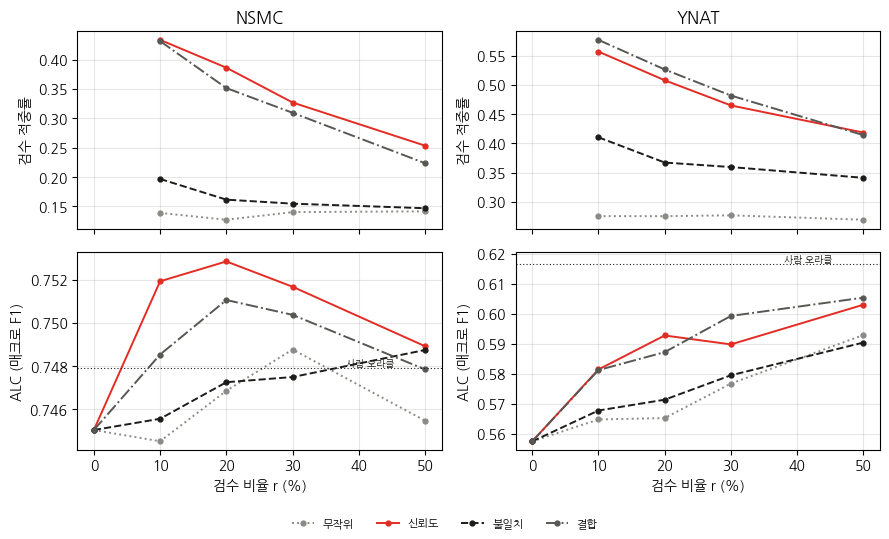

In [17]:
# ── 검수 비율별 적중률과 ALC ────
CRIT = ["무작위", "신뢰도", "불일치", "결합"]
STY = [(GRAY2, ":"), (ACCENT, "-"), (INK, "--"), (GRAY, "-.")]
fig, axes = plt.subplots(2, 2, figsize=(9, 5.4), sharex=True)
for j, name in enumerate(DATA):
    t = tab[tab.data == name].set_index("arm")
    for c, (col, ls) in zip(CRIT, STY):
        rows = [f"{c} {r}%" for r in RATES]
        axes[0, j].plot(RATES, t.loc[rows, "hit"], color=col, ls=ls, marker="o", ms=3.5, lw=1.4, label=c)
        axes[1, j].plot([0, *RATES], [t.loc["r0", "ALC"], *t.loc[rows, "ALC"]], color=col, ls=ls, marker="o", ms=3.5, lw=1.4, label=c)
    axes[1, j].axhline(HUMAN_ALC[name], color=INK, lw=0.8, ls=(0, (1, 2)))
    axes[1, j].text(38, HUMAN_ALC[name], "사람 오라클", va="bottom", fontsize=7, color=INK)
    axes[1, j].set_ylim(top=max(axes[1, j].get_ylim()[1], HUMAN_ALC[name] + 0.004))
    axes[0, j].set(title=name.upper(), ylabel="검수 적중률")
    axes[1, j].set(xlabel="검수 비율 r (%)", ylabel="ALC (매크로 F1)")
    for ax in axes[:, j]:
        ax.grid(alpha=0.3)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig("out/ch15_routing.png", dpi=200)

라운드에 따라 학습 집합의 노이즈가 어떻게 쌓이는지 본다. 검수 비율 20%에서 기준별 누적 노이즈율을 검수 없는 경우(r0)와 함께 그린다.

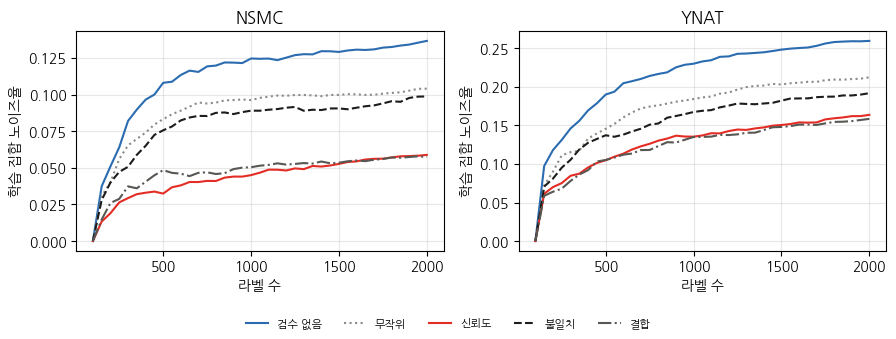

In [18]:
# ── 누적 노이즈율 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, name in zip(axes, DATA):
    g = res[res.data == name]
    for arm, (col, ls) in zip(["r0", *[f"{c} 20%" for c in CRIT]], [("#2B6CB0", "-"), *STY]):
        s = g[g.arm == arm].groupby("n_labeled").noise.mean()
        ax.plot(s.index, s.values, color=col, ls=ls, lw=1.5, label="검수 없음" if arm == "r0" else arm.replace(" 20%", ""))
    ax.set(title=name.upper(), xlabel="라벨 수", ylabel="학습 집합 노이즈율")
    ax.grid(alpha=0.3)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig("out/ch15_noise.png", dpi=200)

## 15.3 학생 모델과 오라클의 불일치 탐지

불일치 기준은 확신 학습(confident learning)의 생각을 빌린다. 학습 집합의 각 라벨에 대해 그 문장을 빼고 학습한 학생 모델(5겹 교차검증)이 그 라벨에 얼마나 낮은 확률을 주는지 본다. 다른 문장들로 배운 규칙과 어긋나는 라벨일수록 틀렸을 가능성이 크다.

신뢰도 기준과 달리 불일치 기준은 이번 라운드 라벨만이 아니라 이전 라운드에 받아들인 Jev 라벨도 다시 검수 후보로 본다. 학생 모델이 자랄수록 예전 라벨의 오류가 드러날 수 있기 때문이다. 표 15.1의 old 열이 검수의 몇 %가 이전 라운드 라벨이었는지 보여 준다.

여기서는 두 기준이 서로 다른 오류를 잡는지 본다. 시드 0, 검수 20%의 마지막 라운드에서 남아 있는 오류(검수되지 않은 틀린 Jev 라벨)의 Jev 신뢰도와 학생 교차검증 확률 분포를 비교한다.

In [19]:
# ── 남은 오류의 모습 ────
def residual(name, arm, seed=0):
    # 마지막 학습 집합에서 검수되지 않은 채 남은 틀린 Jev 라벨의 Jev 신뢰도와 학생 교차검증 확률
    d, f = DATA[name], pd.read_csv(arm_path(name, arm, seed, "final"))
    idx, y = f.idx.values, f.y.values
    Pcv = cv_proba(d["X_pool"][idx], y, d["n_classes"], seed)
    wrong = f.jev.values & (y != d["y_pool"][idx])
    return pd.DataFrame(dict(jev_conf=f.conf.values[wrong], student_p=Pcv[wrong, y[wrong]]))

for name in DATA:
    rows = {arm: residual(name, arm).describe().loc[["count", "mean", "50%"]].stack() for arm in ("신뢰도 20%", "불일치 20%")}
    print(f"\n{name} 마지막 학습 집합에 남은 Jev 오류 (시드 0): 개수와 Jev 신뢰도·학생 교차검증 확률")
    print(pd.DataFrame(rows).round(3).to_string())


nsmc 마지막 학습 집합에 남은 Jev 오류 (시드 0): 개수와 Jev 신뢰도·학생 교차검증 확률
                 신뢰도 20%  불일치 20%
count jev_conf   109.000  191.000
      student_p  109.000  191.000
mean  jev_conf     0.904    0.773
      student_p    0.521    0.519
50%   jev_conf     0.940    0.770
      student_p    0.527    0.513



ynat 마지막 학습 집합에 남은 Jev 오류 (시드 0): 개수와 Jev 신뢰도·학생 교차검증 확률
                 신뢰도 20%  불일치 20%
count jev_conf   308.000  376.000
      student_p  308.000  376.000
mean  jev_conf     0.852    0.753
      student_p    0.184    0.196
50%   jev_conf     0.870    0.770
      student_p    0.165    0.176


## 15.4 노이즈 강건 학습 — 샘플 가중과 라벨 평활화

검수로 다 잡지 못한 노이즈는 학습 쪽에서 견딘다. 학생 모델은 로지스틱 회귀이므로 손실에 가중치나 확률 라벨을 넣을 수 있다.

| 방식 | 학습에 쓰는 라벨 |
|---|---|
| 기본 | Jev 라벨(최대 확률 선택지) |
| 샘플 가중 | Jev 라벨, 가중치 = Jev 신뢰도. 사람 라벨은 1 |
| 확률 라벨 | Jev 선택지 확률 전체. 행을 클래스 수만큼 복제해 확률을 가중치로 준다 |
| 라벨 평활화 | 확률 라벨에 균등 분포를 ε = 0.1 섞는다. 사람 라벨은 그대로 |

검수 없는 경우(r0)와 15.2절에서 검수 20%일 때 ALC가 가장 높았던 기준에 각각 적용한다. Jev 라벨은 저장소에서 다시 쓰므로 새 호출은 거의 없다.

In [20]:
# ── 노이즈 강건 학습 실험 ────
t20 = tab[tab.arm.str.endswith(" 20%")]
BEST20 = t20.groupby("arm").ALC.mean().idxmax()
print("검수 20%에서 두 데이터 평균 ALC가 가장 높은 기준:", BEST20)
ROBUST = {f"{base} · {tr}": (ARMS[base][0], ARMS[base][1], tr) for base in ("r0", BEST20) for tr in ("샘플 가중", "확률 라벨", "라벨 평활화")}
rob = pd.concat(Parallel(n_jobs=len(jobs))(delayed(run_arms)(n, s, ROBUST) for n, s in jobs), ignore_index=True)
base_rows = res[res.arm.isin(["r0", BEST20])].assign(arm=lambda x: x.arm + " · 기본")
tab_rob = arm_table(pd.concat([base_rows, rob], ignore_index=True))
for name in DATA:
    print(f"\n{name} 학습 방식별 (표 15.2)")
    print(tab_rob[tab_rob.data == name].set_index("arm")[["ALC", "ALC_std", "final", "noise"]].round(4).to_string())

검수 20%에서 두 데이터 평균 ALC가 가장 높은 기준: 신뢰도 20%



nsmc 학습 방식별 (표 15.2)
                     ALC  ALC_std   final   noise
arm                                              
r0 · 기본           0.7450   0.0042  0.7825  0.1366
신뢰도 20% · 기본      0.7528   0.0019  0.7902  0.0588
r0 · 샘플 가중        0.7491   0.0044  0.7866  0.1404
r0 · 확률 라벨        0.7530   0.0035  0.7930  0.1362
r0 · 라벨 평활화       0.7541   0.0021  0.7912  0.1391
신뢰도 20% · 샘플 가중   0.7514   0.0028  0.7872  0.0661
신뢰도 20% · 확률 라벨   0.7498   0.0037  0.7893  0.0625
신뢰도 20% · 라벨 평활화  0.7485   0.0034  0.7902  0.0616

ynat 학습 방식별 (표 15.2)
                     ALC  ALC_std   final   noise
arm                                              
r0 · 기본           0.5574   0.0050  0.6584  0.2596
신뢰도 20% · 기본      0.5927   0.0080  0.6895  0.1637
r0 · 샘플 가중        0.5640   0.0048  0.6587  0.2636
r0 · 확률 라벨        0.5909   0.0080  0.6895  0.2651
r0 · 라벨 평활화       0.5896   0.0053  0.6866  0.2638
신뢰도 20% · 샘플 가중   0.5910   0.0048  0.6931  0.1652
신뢰도 20% · 확률 라벨   0.6039   0.0060  0.7086  0.1623
신뢰도 20

## 15.5 검수 예산과 라벨 정확도의 절충

x축에 사람 비용(초기 라벨 100개 + 검수), y축에 ALC를 놓고 기준별 곡선을 그린다. 검수 없는 Jev 오라클(r0)이 왼쪽 끝, 라벨 2,000개를 모두 사람이 붙인 사람 오라클이 오른쪽 끝의 점이다. 같은 비용에서 위에 있는 기준이 낫다.


nsmc: 사람 오라클과의 ALC 차이 중 메운 비율 (r0 = 0, 사람 = 1)
            cost    ALC  recovered
arm                               
r0        5000.0  0.745      0.000
무작위 10%  10700.0  0.745     -0.182
결합 10%   10700.0  0.749      1.223
신뢰도 10%  10700.0  0.752      2.410
불일치 10%  10700.0  0.746      0.183
결합 20%   16400.0  0.751      2.106
무작위 20%  16400.0  0.747      0.635
신뢰도 20%  16400.0  0.753      2.731
불일치 20%  16400.0  0.747      0.775
불일치 30%  22100.0  0.747      0.859
신뢰도 30%  22100.0  0.752      2.321
결합 30%   22100.0  0.750      1.866
무작위 30%  22100.0  0.749      1.305
임계값      31142.0  0.750      1.704
무작위 50%  33500.0  0.745      0.152
불일치 50%  33500.0  0.749      1.297
신뢰도 50%  33500.0  0.749      1.357
결합 50%   33500.0  0.748      0.981

ynat: 사람 오라클과의 ALC 차이 중 메운 비율 (r0 = 0, 사람 = 1)
            cost    ALC  recovered
arm                               
r0        8000.0  0.557      0.000
무작위 10%  17120.0  0.565      0.124
결합 10%   17120.0  0.581      0.403
신뢰도 10%  17120.0  0.581      

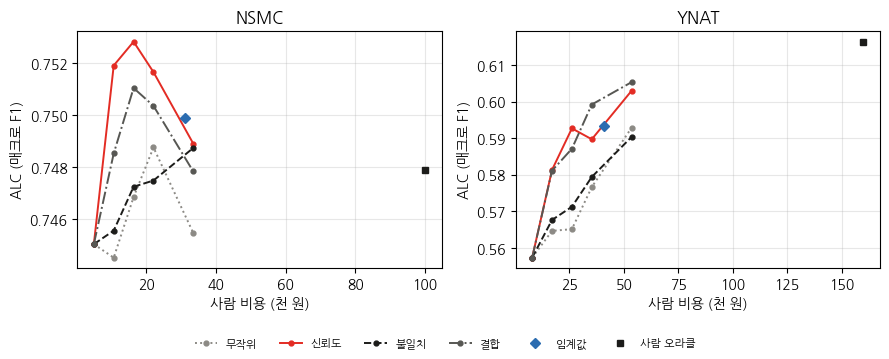

In [21]:
# ── 비용–ALC 절충 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, name in zip(axes, DATA):
    t = tab[tab.data == name].set_index("arm")
    for c, (col, ls) in zip(CRIT, STY):
        rows = ["r0", *[f"{c} {r}%" for r in RATES]]
        ax.plot(t.loc[rows, "cost"] / 1000, t.loc[rows, "ALC"], color=col, ls=ls, marker="o", ms=3.5, lw=1.4, label=c)
    ax.plot(t.loc["임계값", "cost"] / 1000, t.loc["임계값", "ALC"], "D", color="#2B6CB0", ms=5, label="임계값")
    ax.plot(BUDGET * UNIT[name] / 1000, HUMAN_ALC[name], "s", color=INK, ms=5, label="사람 오라클")
    ax.set(title=name.upper(), xlabel="사람 비용 (천 원)", ylabel="ALC (매크로 F1)")
    ax.grid(alpha=0.3)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower center", ncol=6, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig("out/ch15_tradeoff.png", dpi=200)

for name in DATA:
    t = tab[tab.data == name]
    gap = HUMAN_ALC[name] - t.set_index("arm").loc["r0", "ALC"]
    t = t.assign(recovered=(t.ALC - t.set_index("arm").loc["r0", "ALC"]) / gap)
    print(f"\n{name}: 사람 오라클과의 ALC 차이 중 메운 비율 (r0 = 0, 사람 = 1)")
    print(t.set_index("arm")[["cost", "ALC", "recovered"]].sort_values("cost").round(3).to_string())

In [22]:
# ── 이 장이 쓴 Jev 입력 토큰 ────
import glob
files = glob.glob("results/ch15_parts/jev_*.csv")                  # 실제로 보낸 요청의 토큰은 공유 저장소에 있다
total = sum(pd.read_csv(f).n_in.sum() for f in files)
print(f"Jev 라벨 저장소에 기록된 입력 토큰 합: {total:,.0f} (라벨 {sum(len(pd.read_csv(f)) for f in files):,}개)")

Jev 라벨 저장소에 기록된 입력 토큰 합: 14,813,520 (라벨 113,546개)
